# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [12]:
import pandas as pd
import plotly.express as px
import numpy as np
import plotly.graph_objects as go

df = pd.read_csv('world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)

df_long

(234, 16) (1872, 5)


,CCA3,Country,Continent,Year,Population
0,AFG,Afghanistan,Asia,2022,41128771
1,ALB,Albania,Europe,2022,2842321
2,DZA,Algeria,Africa,2022,44903225
3,ASM,American Samoa,Oceania,2022,44273
4,AND,Andorra,Europe,2022,79824
...,...,...,...,...,...
1867,WLF,Wallis and Futuna,Oceania,1970,9377
1868,ESH,Western Sahara,Africa,1970,76371
1869,YEM,Yemen,Asia,1970,6843607
1870,ZMB,Zambia,Africa,1970,4281671


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

I chose a horizontal bar chart to visualize the relative growth of populations across continents. A bar chart is the most effective way to compare a single quantitative metric (growth rate) across categorical groups (continents  

Insight Title: Instead of a generic title, I used an insight title ("[Continent] has grown the fastest...") to immediately answer the core question.

Color Encoding: To highlight the finding and make it accessible (CVD-safe), I avoided red/green. I used a neutral gray for the context (all other continents) and a single accent color (blue) to draw attention to the fastest-growing continent.

Decluttered Layout: I used the plotly_white template and removed gridlines, axis titles, and the legend. Because I added direct data labels (percentages) at the end of each bar, the reader doesn't need to look back and forth between the axis and the bars, making the chart much easier to read.

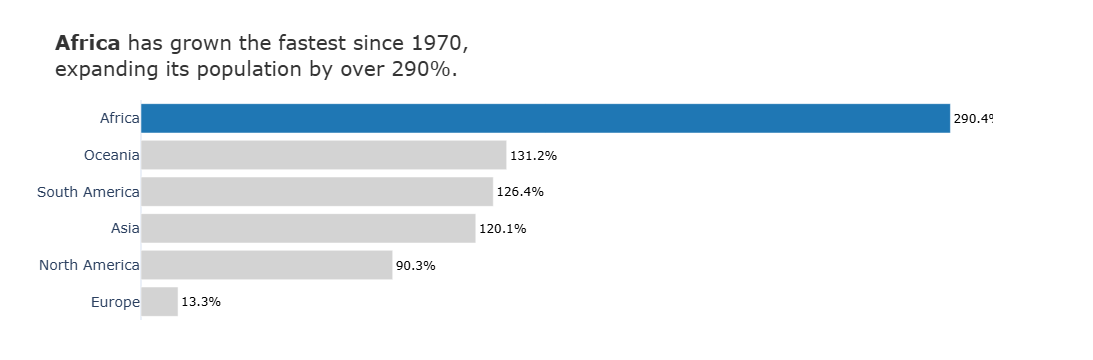

In [13]:
# Q1
# YOUR CODE HERE
df_continent = df_long.groupby(['Continent', 'Year'])['Population'].sum().reset_index()
df_target = df_continent[df_continent['Year'].isin([1970, 2022])]
df_pivot = df_target.pivot(index='Continent', columns='Year', values='Population').reset_index()
df_pivot['Growth_Rate'] = (df_pivot[2022] - df_pivot[1970]) / df_pivot[1970]
df_pivot = df_pivot.sort_values(by='Growth_Rate', ascending=False).reset_index(drop=True)

fastest_continent = df_pivot.iloc[0]['Continent']
fastest_growth_pct = df_pivot.iloc[0]['Growth_Rate'] * 100

colors = ['#1f77b4' if c == fastest_continent else '#d3d3d3' for c in df_pivot['Continent']]

fig = go.Figure(data=[
    go.Bar(
        x=df_pivot['Growth_Rate'] * 100,
        y=df_pivot['Continent'],
        orientation='h',
        marker_color=colors,
        text=df_pivot['Growth_Rate'].apply(lambda x: f"{x*100:.1f}%"),
        textposition='outside',
        textfont=dict(color='black', size=12)
    )
])

fig.update_layout(
    title=dict(
        text=f"<b>{fastest_continent}</b> has grown the fastest since 1970,<br>expanding its population by over {fastest_growth_pct:.0f}%.",
        font=dict(size=20, color='#333333'),
        x=0.05
    ),
    template='plotly_white',
    showlegend=False,
    xaxis_title="",
    yaxis_title="",
    xaxis=dict(
        showgrid=False,  
        showticklabels=False
    ),
    yaxis=dict(
        showgrid=False,
        tickfont=dict(size=14)
    ),
    margin=dict(l=20, r=100, t=100, b=40),
    plot_bgcolor='white'
)

fig.update_yaxes(autorange="reversed")

fig.show()

---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*  
I chose a horizontal bar chart to display the top 15 countries. This chart type is ideal for ranking items with long text labels (country names) and comparing large absolute numbers (millions of people added).

Insight Title: The title directly answers the prompt's main questions, stating exactly how many of the top 15 are in Africa (e.g., "X of the top 15... are in Africa").

CVD-safe Palette & Meaningful Color: To make the data easily scannable and answer the secondary question, I used a neutral grey for non-African countries and a single accent color (blue) to highlight the African countries. The color is CVD-safe (no red/green) and directly encodes the geographical category asked about in the prompt.

Direct Labels & Decluttered Layout: I used plotly_white and removed all gridlines, axis ticks, and axis titles. Instead, I added direct data labels with comma separators at the end of each bar. This allows the reader to quickly grasp the magnitude of the numbers without reading the X-axis.

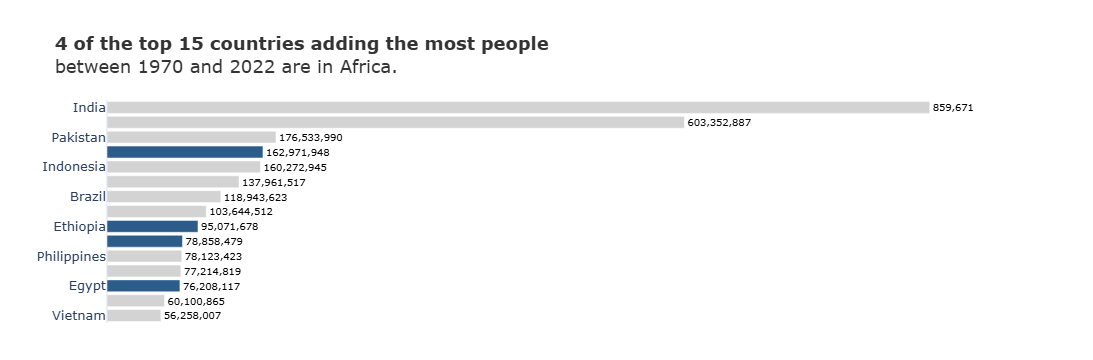

In [15]:
# Q2
# YOUR CODE HERE
df_q2 = df_long[df_long['Year'].isin([1970, 2022])]
df_q2_pivot = df_q2.pivot(index=['Country', 'Continent'], columns='Year', values='Population').reset_index()
df_q2_pivot['Population_Added'] = df_q2_pivot[2022] - df_q2_pivot[1970]

top15 = df_q2_pivot.sort_values(by='Population_Added', ascending=False).head(15).reset_index(drop=True)
africa_count = len(top15[top15['Continent'] == 'Africa'])

colors = ['#2b5c8a' if c == 'Africa' else '#d3d3d3' for c in top15['Continent']]
text_labels = top15['Population_Added'].apply(lambda x: f"{x:,.0f}")

fig = go.Figure(data=[
    go.Bar(
        x=top15['Population_Added'],
        y=top15['Country'],
        orientation='h',
        marker_color=colors,
        text=text_labels,
        textposition='outside',
        textfont=dict(color='black', size=12)
    )
])

text_labels = top15['Population_Added'].apply(lambda x: f"{x:,.0f}")

fig = go.Figure(data=[
    go.Bar(
        x=top15['Population_Added'],
        y=top15['Country'],
        orientation='h',
        marker_color=colors,
        text=text_labels,
        textposition='outside',
        textfont=dict(color='black', size=12)
    )
])

colors = ['#2b5c8a' if c == 'Africa' else '#d3d3d3' for c in top15['Continent']]
text_labels = top15['Population_Added'].apply(lambda x: f"{x:,.0f}")

fig = go.Figure(data=[
    go.Bar(
        x=top15['Population_Added'],
        y=top15['Country'],
        orientation='h',
        marker_color=colors,
        text=text_labels,
        textposition='outside',
        textfont=dict(color='black', size=12)
    )
])

fig.update_layout(
    title=dict(
        text=f"<b>{africa_count} of the top 15 countries adding the most people</b><br>between 1970 and 2022 are in Africa.",
        font=dict(size=18, color='#333333'),
        x=0.05
    ),
    template='plotly_white', 
    showlegend=False, 
    xaxis_title="",
    yaxis_title="",
    xaxis=dict(
        showgrid=False,
        showticklabels=False
    ),
    yaxis=dict(
        showgrid=False,
        tickfont=dict(size=13)
    ),
    margin=dict(l=20, r=120, t=100, b=20),
    plot_bgcolor='white'
)

fig.update_yaxes(autorange="reversed")
fig.show()


---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*  
I chose a scatter plot with logarithmic scales on both axes to visualize the relationship between land area and 2022 population.

Logarithmic Scales: Both area and population span multiple orders of magnitude. Using log scales prevents smaller countries from being clustered at the origin and reveals the underlying power-law relationship.

CVD-safe Palette: I used a qualitative, color-blind friendly palette (Plotly's Safe palette) to distinguish continents without using red/green combinations. Color here encodes a categorical variable (Continent) to answer if the relationship differs by region.

Direct Annotations: I added direct annotations to key outlier countries (e.g., Bangladesh, Russia, Canada). This directly answers the "which countries clearly break the pattern" question, saving the reader from hovering over individual dots.

Insight Title & Decluttered Layout: The title states the main finding—that while a general positive correlation exists, extreme outliers exist. I used plotly_white and removed background gridlines to keep the chart clean.

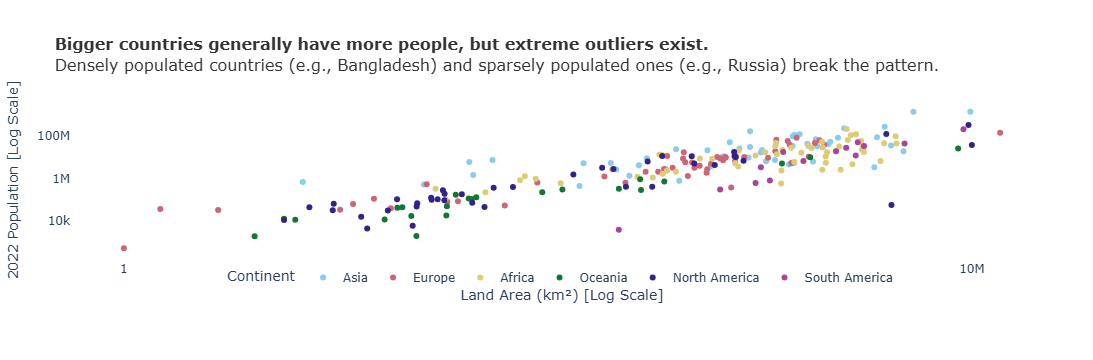

In [16]:
# Q3
# YOUR CODE HERE
df_q3 = df[['Country', 'Continent', 'Area', '2022 Population']].dropna()
df_q3 = df_q3[(df_q3['Area'] > 0) & (df_q3['2022 Population'] > 0)]

fig = px.scatter(
    df_q3,
    x='Area',
    y='2022 Population',
    color='Continent',
    hover_name='Country',
    log_x=True,
    log_y=True, 
    color_discrete_sequence=px.colors.qualitative.Safe 
)

outliers = ['Bangladesh', 'Russia', 'Canada', 'Australia', 'India', 'China']
for country in outliers:
    row = df_q3[df_q3['Country'] == country]
    if not row.empty:
        fig.add_annotation(
            x=row['Area'].values[0],
            y=row['2022 Population'].values[0],
            text=country,
            showarrow=True,
            arrowhead=1,
            ax=20, ay=-20,
            font=dict(size=10, color="black"),
            bgcolor="white",
            bordercolor="black",
            borderwidth=1,
            borderpad=2,
            opacity=0.8
        )

fig.update_layout(
         title=dict(
        text="<b>Bigger countries generally have more people, but extreme outliers exist.</b><br>Densely populated countries (e.g., Bangladesh) and sparsely populated ones (e.g., Russia) break the pattern.",
        font=dict(size=16, color='#333333'),
        x=0.05
    ),
    template='plotly_white',
    xaxis_title="Land Area (km²) [Log Scale]", 
    yaxis_title="2022 Population [Log Scale]",
    xaxis=dict(showgrid=False), 
    yaxis=dict(showgrid=False),
    legend=dict(
        title="Continent",
        orientation="h", 
        yanchor="bottom",
        y=-0.2,
        xanchor="center",
        x=0.5
    ),
    margin=dict(l=40, r=40, t=100, b=100)
)

fig.show()

---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*
I chose a box plot with a logarithmic y-axis to visualize population density across continents.  

Box Plot for Spread: A box plot perfectly addresses the prompt's requirement to "show the spread, not just the average." The boxes show the interquartile range (where the middle 50% of countries lie), the line inside shows the median, and the whiskers/dots show the extremes.

Logarithmic Scale: Population density varies from less than 1 person/km² (e.g., Mongolia) to over 8,000 people/km² (e.g., Singapore). A log scale makes it possible to see the spread of both densely and sparsely populated continents on the same chart.

CVD-safe Palette & Meaningful Color: To adhere to the color rules, I used neutral grey for the context (most continents) and a single accent color (blue) to highlight the continent with the highest median density.

Direct Labels: I annotated the extreme outliers (e.g., Singapore, Mongolia/Greenland) to immediately answer "how" the density varies, providing concrete examples of the massive spread.

Decluttered Layout: Removed all gridlines and unnecessary legends, using the plotly_white template to keep the focus strictly on the data distribution.

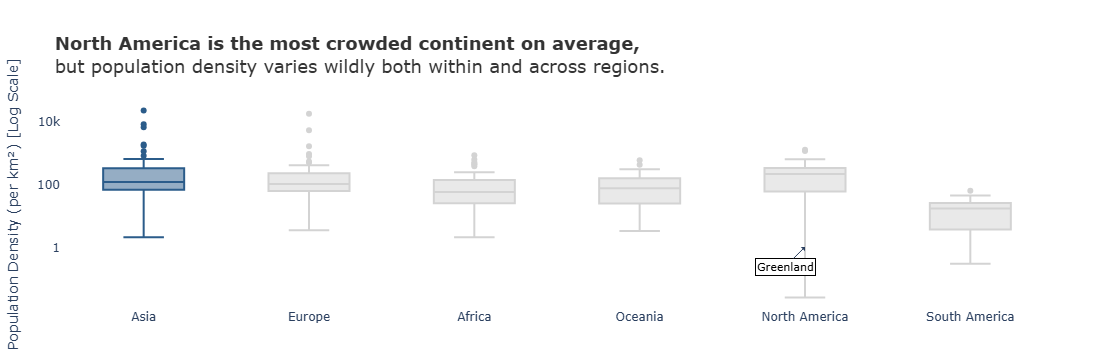

In [18]:
# Q4
# YOUR CODE HERE
df_q4 = df[['Country', 'Continent', 'Density']].dropna()
df_q4 = df_q4[df_q4['Density'] > 0]
median_density = df_q4.groupby('Continent')['Density'].median().sort_values(ascending=False)
most_crowded_continent = median_density.index[0]

top_dense_country = df_q4.sort_values(by='Density', ascending=False).iloc[0]
low_dense_country = df_q4.sort_values(by='Density', ascending=True).iloc[0]

colors = {'Asia': '#2b5c8a'} 

for continent in df_q4['Continent'].unique():
    if continent not in colors:
        colors[continent] = '#d3d3d3'

fig = px.box(
    df_q4,
    x='Continent',
    y='Density',
    color='Continent',
    color_discrete_map=colors,
    points='outliers',
    log_y=True 
)

fig.add_annotation(
    x=top_dense_country['Continent'], y=top_dense_country['Density'],
    text=top_dense_country['Country'], showarrow=True, arrowhead=1, ax=20, ay=-20,
    font=dict(size=11, color="black"), bgcolor="white", bordercolor="black"
)
fig.add_annotation(
    x=low_dense_country['Continent'], y=low_dense_country['Density'],
    text=low_dense_country['Country'], showarrow=True, arrowhead=1, ax=-20, ay=20,
    font=dict(size=11, color="black"), bgcolor="white", bordercolor="black"
)

fig.update_layout(
    title=dict(
        text=f"<b>{most_crowded_continent} is the most crowded continent on average,</b><br>but population density varies wildly both within and across regions.",
        font=dict(size=18, color='#333333'),
        x=0.05
    ),
    template='plotly_white',
    showlegend=False, 
    xaxis_title="",
    yaxis_title="Population Density (per km²) [Log Scale]",
    xaxis=dict(showgrid=False),
    yaxis=dict(showgrid=False),
    margin=dict(l=40, r=40, t=100, b=40)
)

fig.show()

---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

I chose a Choropleth map to visualize the percentage change in population between 2000 and 2022.  
Map for Location: Since the prompt specifically asks "where in the world are they", a map is the most direct and intuitive way to show spatial patterns (e.g., the regional clustering of shrinking populations in Eastern Europe).

Diverging CVD-safe Palette: I used a custom diverging color scale to encode the direction of change (meaningful color). To remain CVD-safe (avoiding red/green), I used blue to represent shrinking populations, grey for near-zero change, and orange for growing populations. The color_continuous_midpoint is set to 0 to ensure the neutral color anchors the scale accurately.

Insight Title: The title directly states the geographic finding, pointing out the regional trends (shrinking in Eastern Europe, growing in Africa/Middle East) rather than just describing the map.

Direct Text Annotations: I added text boxes pointing to key geographic regions to explicitly highlight the main areas of growth and shrinkage, helping the reader instantly find the story.

Decluttered Design: I used plotly_white and configured the map geography to be minimal (soft grey land, pale blue ocean) to ensure the data colors pop out.

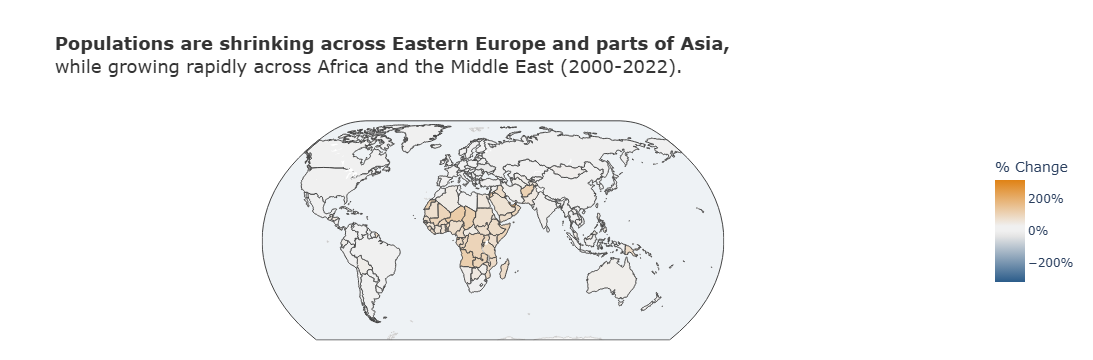

In [19]:
# Q5
# YOUR CODE HERE
df_q5 = df_long[df_long['Year'].isin([2000, 2022])]
df_q5_pivot = df_q5.pivot(index=['CCA3', 'Country', 'Continent'], columns='Year', values='Population').reset_index()
df_q5_pivot = df_q5_pivot.rename(columns={2000: 'Pop_2000', 2022: 'Pop_2022'})
df_q5_pivot = df_q5_pivot.dropna(subset=['Pop_2000', 'Pop_2022'])

df_q5_pivot['Pct_Change'] = ((df_q5_pivot['Pop_2022'] - df_q5_pivot['Pop_2000']) / df_q5_pivot['Pop_2000']) * 100

top_growth = df_q5_pivot.sort_values(by='Pct_Change', ascending=False).head(2)
top_shrink = df_q5_pivot.sort_values(by='Pct_Change', ascending=True).head(3)

fig = px.choropleth(
    df_q5_pivot,
    locations="CCA3",  
    locationmode="ISO-3",  
    color="Pct_Change", 
    hover_name="Country",  
    hover_data={"Continent": True, "Pct_Change": ":.1f%", "CCA3": False},
    color_continuous_scale=[
        [0.0, '#2b5c8a'],  
        [0.45, '#e5e5e5'], 
        [0.5, '#f0f0f0'],
        [0.55, '#f0f0f0'], 
        [1.0, '#e08214']
    ],
    color_continuous_midpoint=0 
)

fig.update_geos(
    showcoastlines=True, coastlinecolor="#cccccc",
    showland=True, landcolor="#f9f9f9",
    showocean=True, oceancolor="#eef2f5",
    showcountries=True, countrycolor="#ffffff",
    projection_type="natural earth" 
)

annotations = [
    dict(x=-100, y=40, text="<b>Shrinking:</b><br>Eastern Europe &<br>Southern Europe", showarrow=False, font=dict(color='#2b5c8a', size=12)),
    dict(x=20, y=0, text="<b>Growing:</b><br>Sub-Saharan Africa<br>& Middle East", showarrow=False, font=dict(color='#e08214', size=12))
]
fig.update_layout(annotations=annotations)

fig.update_layout(
    title=dict(
        text="<b>Populations are shrinking across Eastern Europe and parts of Asia,</b><br>while growing rapidly across Africa and the Middle East (2000-2022).",
        font=dict(size=18, color='#333333'),
        x=0.05
    ),
    template='plotly_white',
    coloraxis_colorbar=dict(
        title="% Change",
        ticksuffix="%",
        len=0.6,
        yanchor="middle",
        y=0.5
    ),
    margin=dict(l=20, r=20, t=100, b=20),
    xaxis=dict(showgrid=False, showticklabels=False),
    yaxis=dict(showgrid=False, showticklabels=False)
)

fig.show()

---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*  
I chose a Treemap to visualize the distribution of the 2022 world population.  

Treemap for Hierarchy & Part-to-Whole: A treemap is uniquely suited for this prompt because it simultaneously shows both levels: the outer boundaries represent the continents, and the nested rectangles represent the countries within them. The area of each rectangle is perfectly proportional to its population, giving an immediate visual sense of where 8 billion people live.

CVD-safe Palette & Meaningful Color: To strictly follow the design rules, I used neutral grey for context (all other continents) and a single accent color (blue) to highlight the most populous continent. This immediately draws the eye to the main finding without being decorative.

Direct Labels: Instead of relying on a legend or axes (which a treemap lacks), I added direct text labels inside the blocks showing both the country name and a formatted population number (e.g., "1.4B"). This allows the reader to instantly see exact magnitudes.

Insight Title: The title explicitly states the main finding—that Asia holds the vast majority of the population—rather than just labeling the chart variables.

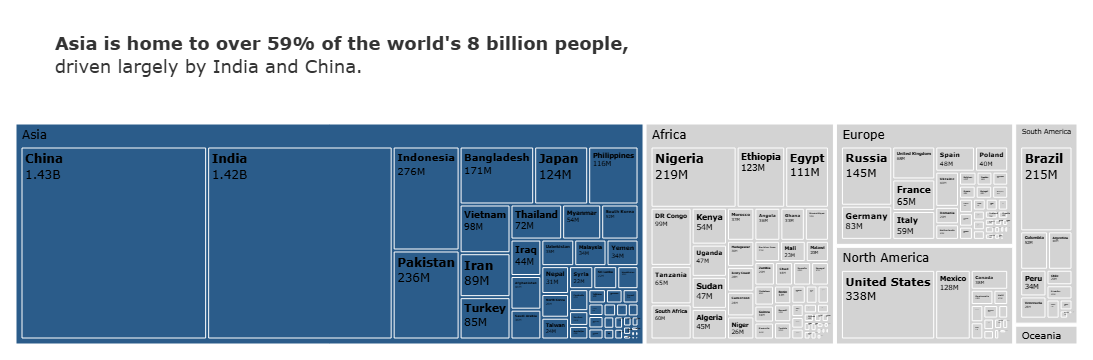

In [20]:
# Q6
# YOUR CODE HERE
df_q6 = df_long[df_long['Year'] == 2022].copy()
continent_totals = df_q6.groupby('Continent')['Population'].sum().sort_values(ascending=False)
top_continent = continent_totals.index[0]
top_continent_share = (continent_totals.iloc[0] / continent_totals.sum()) * 100

color_map = {c: '#d3d3d3' for c in df_q6['Continent'].unique()}
color_map[top_continent] = '#2b5c8a'

def format_pop(num):
    if num >= 1e9:
        return f"{num/1e9:.2f}B"
    elif num >= 1e6:
        return f"{num/1e6:.0f}M"
    else:
        return f"{num/1e3:.0f}K"

df_q6['Pop_Label'] = df_q6['Population'].apply(format_pop)

fig = px.treemap(
    df_q6,
    path=['Continent', 'Country'], 
    values='Population',    
    color='Continent',  
    color_discrete_map=color_map,   
    custom_data=['Pop_Label']       
)

fig.update_traces(
    texttemplate="<b>%{label}</b><br>%{customdata[0]}",
    textfont=dict(size=12, color="black"),
    hovertemplate="<b>%{label}</b><br>Population: %{value:,.0f}<extra></extra>"
)

fig.update_layout(
    title=dict(
        text=f"<b>{top_continent} is home to over {top_continent_share:.0f}% of the world's 8 billion people,</b><br>driven largely by India and China.",
        font=dict(size=18, color='#333333'),
        x=0.05
    ),
    template='plotly_white',
    margin=dict(l=10, r=10, t=100, b=10),
    coloraxis_showscale=False 
)

fig.show()

---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

I chose a line chart to visualize how the regional shares of the world population changed over time from 1970 to 2022  

Line Chart for Trends: A line chart is the most effective way to show continuous change over time. It clearly illustrates the trajectories of each region's share, making it immediately obvious which regions are rising and which are falling.

Data Aggregation: Per the prompt's instruction, I grouped North America, South America, and Oceania into a single "Rest of the world" category to simplify the chart and focus on the major players.

CVD-safe Palette & Meaningful Color: I used a color-blind friendly palette (no red/green). To highlight the main finding (who is rising), I applied a single accent color (blue) to the fastest-growing region (Africa). All other regions are assigned different shades of grey, serving as a neutral context that doesn't distract from the core message.

Direct Labels: Instead of relying on a legend and a Y-axis, I placed direct labels at the end of each line showing the region name and its exact 2022 share. This allows the reader to instantly connect the trend line to the specific region and its final value without scanning back and forth.

Decluttered Layout: Used the plotly_white template and removed all gridlines, Y-axis tick labels, and axis titles to keep the focus purely on the trend lines and the annotations. The insight title explicitly states the conclusion.

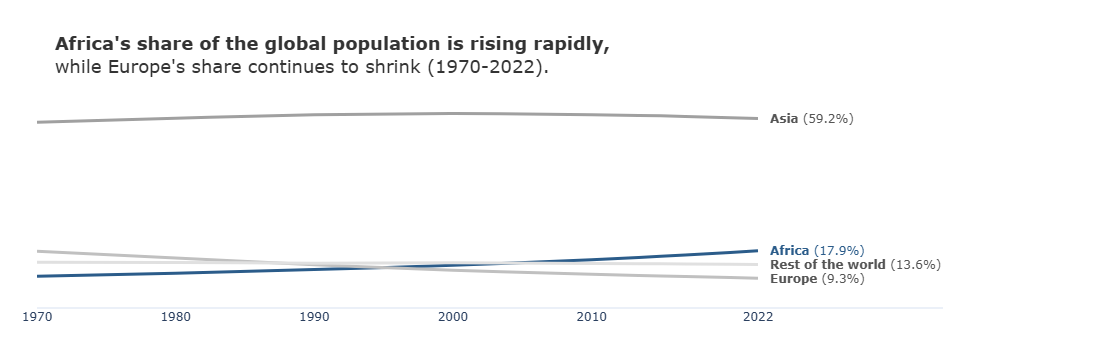

In [21]:
# Q7
# YOUR CODE HERE
df_q7 = df_long.copy()

other_continents = ['North America', 'South America', 'Oceania']
df_q7['Region'] = df_q7['Continent'].replace(other_continents, 'Rest of the world')
df_q7_grouped = df_q7.groupby(['Year', 'Region'])['Population'].sum().reset_index()
df_q7_grouped['World_Total'] = df_q7_grouped.groupby('Year')['Population'].transform('sum')
df_q7_grouped['Share'] = (df_q7_grouped['Population'] / df_q7_grouped['World_Total']) * 100

share_change = df_q7_grouped[df_q7_grouped['Year'] == 2022].set_index('Region')['Share'] - \
               df_q7_grouped[df_q7_grouped['Year'] == 1970].set_index('Region')['Share']
fastest_rising = share_change.idxmax()
rising_pct = share_change.max()

color_map = {
    'Africa': '#2b5c8a',     
    'Asia': '#a0a0a0',      
    'Europe': '#c0c0c0',    
    'Rest of the world': '#e0e0e0'
}

fig = px.line(
    df_q7_grouped,
    x='Year',
    y='Share',
    color='Region',
    color_discrete_map=color_map,
    line_shape='spline' 
)

fig.update_traces(line=dict(width=3))

for region in df_q7_grouped['Region'].unique():
    last_year_data = df_q7_grouped[(df_q7_grouped['Region'] == region) & (df_q7_grouped['Year'] == 2022)].iloc[0]
    fig.add_annotation(
        x=last_year_data['Year'],
        y=last_year_data['Share'],
        text=f"<b>{region}</b> ({last_year_data['Share']:.1f}%)",
        showarrow=False,
        xanchor='left',
        xshift=10, 
        font=dict(color=color_map[region] if region == 'Africa' else '#555555', size=12)
    )

fig.update_layout(
    title=dict(
        text=f"<b>{fastest_rising}'s share of the global population is rising rapidly,</b><br>while Europe's share continues to shrink (1970-2022).",
        font=dict(size=18, color='#333333'),
        x=0.05
    ),
    template='plotly_white', 
    showlegend=False,  
    xaxis_title="",
    yaxis_title="",
    xaxis=dict(
        showgrid=False, 
        tickmode='array',
        tickvals=[1970, 1980, 1990, 2000, 2010, 2022], 
        tickfont=dict(size=12)
    ),
    yaxis=dict(
        showgrid=False,
        showticklabels=False, 
        range=[0, 65]       
    ),
    margin=dict(l=20, r=150, t=100, b=40),
    plot_bgcolor='white'
)
fig.show()